# White House Logs

## Introduction

This project focuses on the White House Visitor Logs with a specific focus on operational efficiency and security management. By analyzing arrival patterns, meeting locations, and peak volumes across multiple datasets, we can identify bottlenecks that compromise security and delay administrative functions.

This project evaluates visitor volume patterns across the first half of 2023 to address potential security 'logjams.' The goal is to develop a data-driven strategy to reallocate resources to high-congestion entry points and implement modern clearance protocols in the busiest departments. The call to action is to reduce wait times without compromising facility safety.  

### 2.1 Data Preparation

Load the dataset as a Pandas data frame

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load the dataset file to Pandas DataFrame
data_01_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.01_WAVES-ACCESS-RECORDS.csv')
data_02_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.02_WAVES-ACCESS-RECORDS.csv')
data_03_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.03_WAVES-ACCESS-RECORDS.csv')
data_04_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.04_WAVES-ACCESS-RECORDS.csv')
data_05_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.05_WAVES-ACCESS-RECORDS.csv')
data_06_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.06_WAVES-ACCESS-RECORDS.csv')


C:\Users\MAYMA\AppData\Local\Temp\ipykernel_27140\650329321.py:2: DtypeWarning: Columns (7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  data_01_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.01_WAVES-ACCESS-RECORDS.csv')
C:\Users\MAYMA\AppData\Local\Temp\ipykernel_27140\650329321.py:3: DtypeWarning: Columns (7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  data_02_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.02_WAVES-ACCESS-RECORDS.csv')
C:\Users\MAYMA\AppData\Local\Temp\ipykernel_27140\650329321.py:4: DtypeWarning: Columns (7,8,13) have mixed types. Specify dtype option on import or set low_memory=False.
  data_03_23 = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/2023.03_WAVES-ACCESS-

In [3]:
# Preview the column names to verify structure
print(data_01_23.columns)

Index(['Last Name', 'First Name', 'Middle Initial', 'UIN', 'BDGNBR',
       'Access Type', 'TOA', 'POA', 'TOD', 'POD', 'Appointment Made Date',
       'Appointment Start Date', 'Appointment End Date',
       'Appointment Cancel Date', 'Total People', 'Last Updated By', 'POST',
       'Last Entry Date', 'Terminal Suffix', 'Visitee Last Name',
       'Visitee First Name', 'Meeting Location', 'Meeting Room',
       'Caller Last Name', 'Caller First Name', 'CALLER_ROOM', 'RELEASEDATE'],
      dtype='object')


In [4]:
# Preview the column names to verify structure
print(data_06_23.columns)

Index(['Last Name', 'First Name', 'Middle Initial', 'UIN', 'BDGNBR',
       'Access Type', 'TOA', 'POA', 'TOD', 'POD', 'Appointment Made Date',
       'Appointment Start Date', 'Appointment End Date',
       'Appointment Cancel Date', 'Total People', 'Last Updated By', 'POST',
       'Last Entry Date', 'Terminal Suffix', 'Visitee Last Name',
       'Visitee First Name', 'Meeting Location', 'Meeting Room',
       'Caller Last Name', 'Caller First Name', 'Caller Room', 'Release Date'],
      dtype='object')


In [5]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(data_01_23.head())


The first five rows of data:
  Last Name First Name Middle Initial     UIN    BDGNBR Access Type  \
0     AABYE       MARY              A  U13230  197546.0          VA   
1     AALST      CARLO              B  U10746       NaN          VA   
2  AARONSON      SCOTT              I  U21068  201034.0          VA   
3      ABAD       JOHN              C  U11018       NaN          VA   
4    ABADIE     NATHAN              D  U15945       NaN          VA   

                   TOA  POA  TOD  POD  ...  Last Entry Date Terminal Suffix  \
0  Jan 19 2023  8:58AM  NaN  NaN  B04  ...   1/5/2023 18:07              DE   
1  Jan  3 2023  9:37AM  NaN  NaN  NaN  ...  12/27/2022 5:57              VW   
2  Jan 31 2023 10:42AM  NaN  NaN  D03  ...   1/31/2023 5:32              PK   
3                  NaN  NaN  NaN  NaN  ...  12/28/2022 8:10              VW   
4  Jan 21 2023  9:46AM  NaN  NaN  NaN  ...  1/14/2023 12:56              VW   

  Visitee Last Name Visitee First Name  Meeting Location         Mee

In [6]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(data_06_23.head())


The first five rows of data:
      Last Name First Name Middle Initial     UIN  BDGNBR Access Type  \
0         AAKER      PIPER              A  U86209     NaN          VA   
1  AALIMJOHNSON       KAIF              A  U88227     NaN          VA   
2       AALOORI     BANGAR              R  U96079     NaN          VA   
3       AALSETH     HANNAH              J  U89264     NaN          VA   
4       AALSETH    KENNETH              E  U89264     NaN          VA   

                   TOA  POA  TOD  POD  ...  Last Entry Date Terminal Suffix  \
0  Jun 11 2023  9:36AM  NaN  NaN  NaN  ...    6/5/2023 9:33              VW   
1  Jun 13 2023  6:54PM  NaN  NaN  NaN  ...  6/13/2023 19:02              PS   
2                  NaN  NaN  NaN  NaN  ...  6/21/2023 20:50              GM   
3  Jun 16 2023  9:33AM  NaN  NaN  NaN  ...    6/9/2023 7:49              VW   
4  Jun 16 2023  9:33AM  NaN  NaN  NaN  ...    6/9/2023 7:49              VW   

  Visitee Last Name Visitee First Name  Meeting Location

#### 2.1(a) Data Frame Integration

In [7]:
import pandas as pd

# List of existing DataFrames
dfs = [data_01_23, data_02_23, data_03_23, data_04_23, data_05_23, data_06_23]

In [8]:
clean_dfs = []

for i, df in enumerate(dfs):
    # Create a copy to avoid modifying the originals
    temp_df = df.copy()
    
    # Standardize: ALL CAPS and strip leading/trailing whitespace
    temp_df.columns = temp_df.columns.str.upper().str.strip()
    
    # Add a 'MONTH_ID' column (1-6) to make time-series analysis easier later
    temp_df['MONTH_ID'] = i + 1
    
    clean_dfs.append(temp_df)

print("Columns standardized across all 6 DataFrames.")

Columns standardized across all 6 DataFrames.


In [9]:
# Merge all 6 months into one
master_df = pd.concat(clean_dfs, ignore_index=True)

# Check the shape to ensure all rows are accounted for
print(f"Total rows in master_df: {master_df.shape[0]}")
print(f"Standardized Columns: {master_df.columns.tolist()}")

Total rows in master_df: 398210
Standardized Columns: ['LAST NAME', 'FIRST NAME', 'MIDDLE INITIAL', 'UIN', 'BDGNBR', 'ACCESS TYPE', 'TOA', 'POA', 'TOD', 'POD', 'APPOINTMENT MADE DATE', 'APPOINTMENT START DATE', 'APPOINTMENT END DATE', 'APPOINTMENT CANCEL DATE', 'TOTAL PEOPLE', 'LAST UPDATED BY', 'POST', 'LAST ENTRY DATE', 'TERMINAL SUFFIX', 'VISITEE LAST NAME', 'VISITEE FIRST NAME', 'MEETING LOCATION', 'MEETING ROOM', 'CALLER LAST NAME', 'CALLER FIRST NAME', 'CALLER_ROOM', 'RELEASEDATE', 'MONTH_ID', 'CALLER ROOM', 'RELEASE DATE']


In [10]:
# Convert to datetime objects
if 'APPT_START_DATE' in master_df.columns:
    master_df['APPT_START_DATE'] = pd.to_datetime(master_df['APPT_START_DATE'], errors='coerce')

# Drop any rows that are completely empty (common in public logs)
master_df = master_df.dropna(how='all')

# View the first few rows to verify
master_df.head()

,LAST NAME,FIRST NAME,MIDDLE INITIAL,UIN,BDGNBR,ACCESS TYPE,TOA,POA,TOD,POD,...,VISITEE FIRST NAME,MEETING LOCATION,MEETING ROOM,CALLER LAST NAME,CALLER FIRST NAME,CALLER_ROOM,RELEASEDATE,MONTH_ID,CALLER ROOM,RELEASE DATE
0,AABYE,MARY,A,U13230,197546.0,VA,Jan 19 2023 8:58AM,NaN,NaN,B04,...,Diana,OEOB,Bowling Alley - 037,EPSTEIN,DIANA,NaN,4/30/2023,1,NaN,NaN
1,AALST,CARLO,B,U10746,NaN,VA,Jan 3 2023 9:37AM,NaN,NaN,NaN,...,Visitors,WH,EW TOUR,WAVES,VISITORSOFFICE,NaN,4/30/2023,1,NaN,NaN
2,AARONSON,SCOTT,I,U21068,201034.0,VA,Jan 31 2023 10:42AM,NaN,NaN,D03,...,Caitlin,OEOB,425,KHAN,PUNEET,NaN,4/30/2023,1,NaN,NaN
3,ABAD,JOHN,C,U11018,NaN,VA,NaN,NaN,NaN,NaN,...,Visitors,WH,EW TOUR,WAVES,VISITORSOFFICE,NaN,4/30/2023,1,NaN,NaN
4,ABADIE,NATHAN,D,U15945,NaN,VA,Jan 21 2023 9:46AM,NaN,NaN,NaN,...,Visitors,WH,EW TOUR,WAVES,VISITORSOFFICE,NaN,4/30/2023,1,NaN,NaN


#### 2.1(b) Check for missing values

In [11]:
# Using .isnull() to find missing values
master_df.isnull().sum()


LAST NAME                      30
FIRST NAME                      0
MIDDLE INITIAL                514
UIN                           514
BDGNBR                     343033
ACCESS TYPE                     0
TOA                        115899
POA                        395813
TOD                        395818
POD                        358399
APPOINTMENT MADE DATE           1
APPOINTMENT START DATE          0
APPOINTMENT END DATE            0
APPOINTMENT CANCEL DATE    398085
TOTAL PEOPLE                  514
LAST UPDATED BY                 0
POST                            0
LAST ENTRY DATE                 0
TERMINAL SUFFIX                 0
VISITEE LAST NAME               1
VISITEE FIRST NAME          26744
MEETING LOCATION                0
MEETING ROOM                    0
CALLER LAST NAME                0
CALLER FIRST NAME               0
CALLER_ROOM                398210
RELEASEDATE                317866
MONTH_ID                        0
CALLER ROOM                398210
RELEASE DATE  

Datasets with some missing values. 

#### 2.1(c) Check for duplicates

In [12]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate_countries = master_df.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate_countries}")


Number of duplicate rows: 545


Datasets with some duplicate rows.

#### 2.1(d) Data Cleanup

In [13]:
# 1. Combine split columns
# Dataset have 'RELEASEDATE' and 'RELEASE DATE'. Merge them and drop the redundant ones.
master_df['RELEASE_DATE_FIXED'] = master_df['RELEASE DATE'].fillna(master_df['RELEASEDATE'])

# 2. Convert Time columns to Datetime objects
# This is CRITICAL for Line Charts and Scatterplots with Time
date_cols = ['APPOINTMENT START DATE', 'APPOINTMENT END DATE', 'APPOINTMENT MADE DATE']

for col in date_cols:
    master_df[col] = pd.to_datetime(master_df[col], errors='coerce')

# 3. Handle the 'TOTAL PEOPLE' column
# Since it's a float, fill NaNs with 1 (assuming at least one person visited) 
# and convert to integer for cleaner charts.
master_df['TOTAL PEOPLE'] = master_df['TOTAL PEOPLE'].fillna(1).astype(int)

# 4. Create an 'HOUR' column for "Peak Flow" analysis
# This makes plotting hourly line charts much easier.
master_df['START_HOUR'] = master_df['APPOINTMENT START DATE'].dt.hour

# 5. Drop the empty columns to save memory
# CALLER_ROOM and CALLER ROOM are 0 non-null
master_df = master_df.drop(columns=['CALLER_ROOM', 'CALLER ROOM'])

print("Cleanup complete. Data is now ready for visualization.")

Cleanup complete. Data is now ready for visualization.


#### 2.1(e) Validate Numerical Variables

In [14]:
# Preview the column names and counts and data types
print(master_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398210 entries, 0 to 398209
Data columns (total 30 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   LAST NAME                398180 non-null  object        
 1   FIRST NAME               398210 non-null  object        
 2   MIDDLE INITIAL           397696 non-null  object        
 3   UIN                      397696 non-null  object        
 4   BDGNBR                   55177 non-null   float64       
 5   ACCESS TYPE              398210 non-null  object        
 6   TOA                      282311 non-null  object        
 7   POA                      2397 non-null    object        
 8   TOD                      2392 non-null    object        
 9   POD                      39811 non-null   object        
 10  APPOINTMENT MADE DATE    398209 non-null  datetime64[ns]
 11  APPOINTMENT START DATE   398210 non-null  datetime64[ns]
 12  APPOINTMENT END 

In [15]:
# Check for invalid or extreme values
master_df[['BDGNBR', 'TOTAL PEOPLE', 'START_HOUR']].describe()


,BDGNBR,TOTAL PEOPLE,START_HOUR
count,55177.000000,398210.000000,398210.000000
mean,200771.050275,71.802388,11.171086
std,2897.446879,268.567554,3.051676
min,186980.000000,1.000000,0.000000
25%,197919.000000,4.000000,9.000000
50%,201016.000000,6.000000,11.000000
75%,203867.000000,25.000000,12.000000
max,206371.000000,2775.000000,23.000000


### 2.2 Exploratory Data Analysis

Exploratory data analysis revealed several patterns in the dataset. Several visualizations provide clear and complementary insights into these dataset. 

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [17]:

# Ensure date columns are datetime objects
master_df['APPOINTMENT START DATE'] = pd.to_datetime(master_df['APPOINTMENT START DATE'], errors='coerce')
master_df['APPOINTMENT END DATE'] = pd.to_datetime(master_df['APPOINTMENT END DATE'], errors='coerce')

# Calculate helper columns
master_df['START_HOUR'] = master_df['APPOINTMENT START DATE'].dt.hour
master_df['DAY_OF_WEEK'] = master_df['APPOINTMENT START DATE'].dt.day_name()
master_df['DURATION_MIN'] = (master_df['APPOINTMENT END DATE'] - master_df['APPOINTMENT START DATE']).dt.total_seconds() / 60

# Fill missing Total People with 1 (standard audit assumption)
master_df['TOTAL PEOPLE'] = master_df['TOTAL PEOPLE'].fillna(1).astype(int)

#### 2.2(a) Create a line chart of Hourly Volume

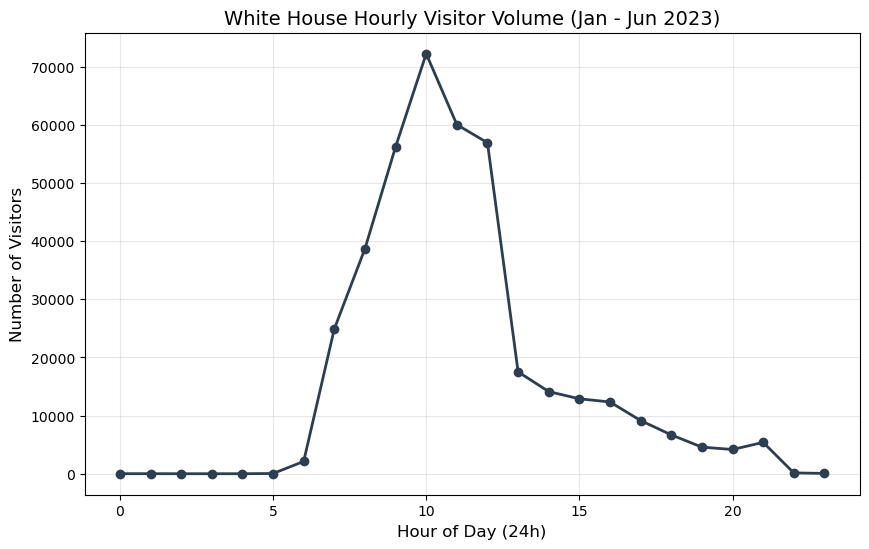

In [18]:
plt.figure(figsize=(10, 6))
hourly_counts = master_df.groupby('START_HOUR').size()
plt.plot(hourly_counts.index, hourly_counts.values, marker='o', color='#2c3e50', linewidth=2)
plt.title('White House Hourly Visitor Volume (Jan - Jun 2023)', fontsize=14)
plt.xlabel('Hour of Day (24h)', fontsize=12)
plt.ylabel('Number of Visitors', fontsize=12)
plt.grid(True, alpha=0.3)


#### 2.2(b) Create a stacked barchart with Day of Week by Location

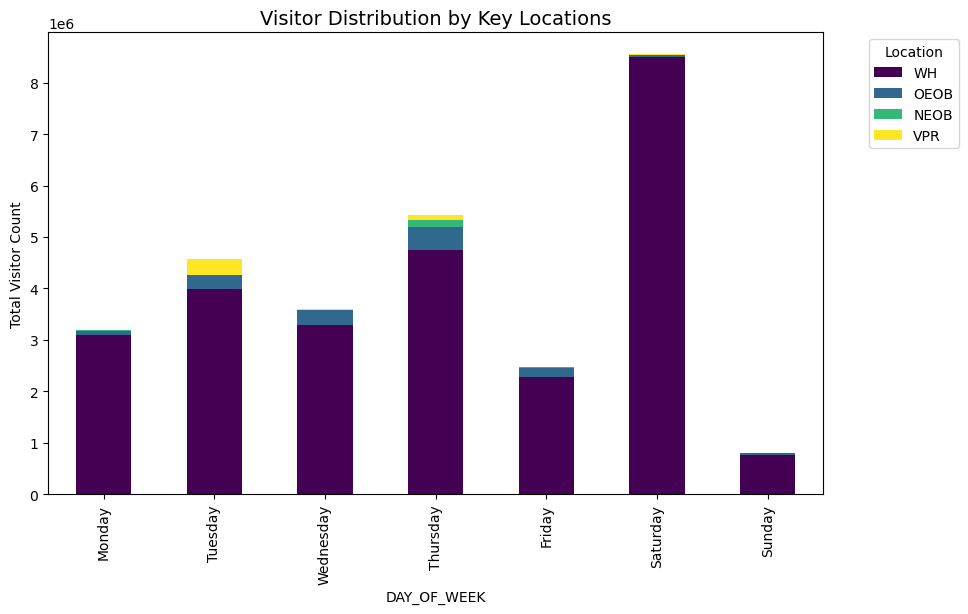

In [19]:
# Grouping by day and location to see where the staff load is highest
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_df = master_df.pivot_table(index='DAY_OF_WEEK', columns='MEETING LOCATION', values='TOTAL PEOPLE', aggfunc='sum').reindex(day_order)
# Focus on top 5 locations to reduce 'noise'
top_locs = master_df['MEETING LOCATION'].value_counts().nlargest(5).index
pivot_df[top_locs].plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Visitor Distribution by Key Locations', fontsize=14)
plt.ylabel('Total Visitor Count')
plt.legend(title='Location', bbox_to_anchor=(1.05, 1), loc='upper left')


#### 2.2(c) Create a Scatterplot with Time: Arrival Time vs Group Size (Signal to Noise)

Text(0, 0.5, 'People per Group')

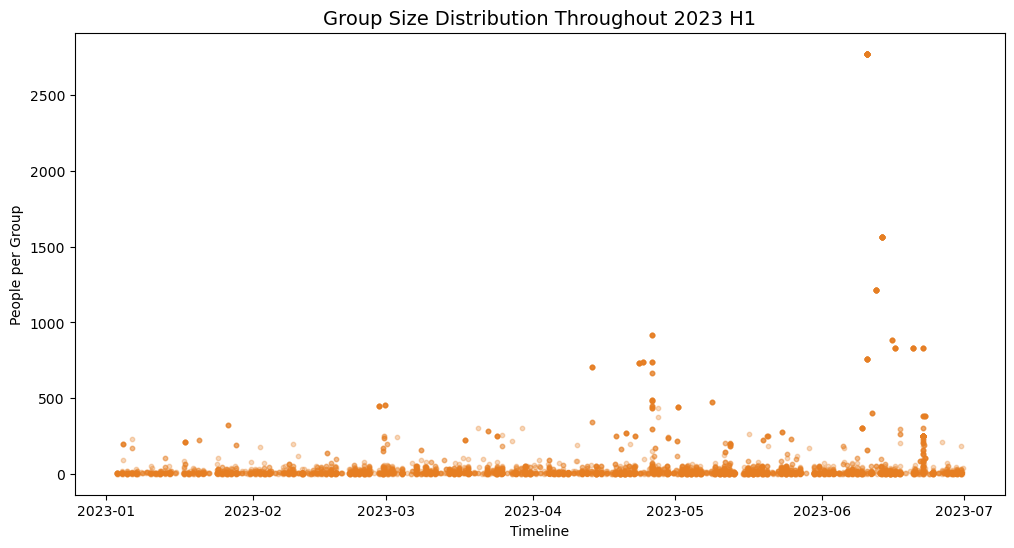

In [20]:
plt.figure(figsize=(12, 6))
# Sampling 5000 points to keep the 'signal' clear without overlapping 'noise'
sample_df = master_df.sample(min(5000, len(master_df)))
plt.scatter(sample_df['APPOINTMENT START DATE'], sample_df['TOTAL PEOPLE'], alpha=0.3, color='#e67e22', s=10)
plt.title('Group Size Distribution Throughout 2023 H1', fontsize=14)
plt.xlabel('Timeline')
plt.ylabel('People per Group')


#### 2.2(d) Create a Horizontal Bar Chart of Top Visitees (Sorted)

Text(0.5, 0, 'Total Meetings Logged')

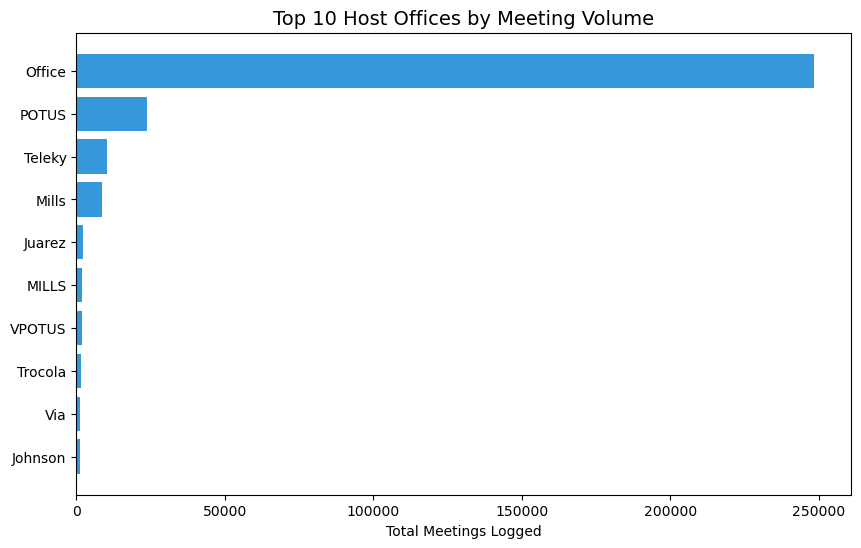

In [21]:
plt.figure(figsize=(10, 6))
visitee_counts = master_df['VISITEE LAST NAME'].value_counts().head(10).sort_values(ascending=True)
plt.barh(visitee_counts.index, visitee_counts.values, color='#3498db')
plt.title('Top 10 Host Offices by Meeting Volume', fontsize=14)
plt.xlabel('Total Meetings Logged')

#### 2.2(e) Create a Step Chart of Cumulative Hourly Arrivals (Tufte-Style)

Text(0, 0.5, 'Cumulative Total')

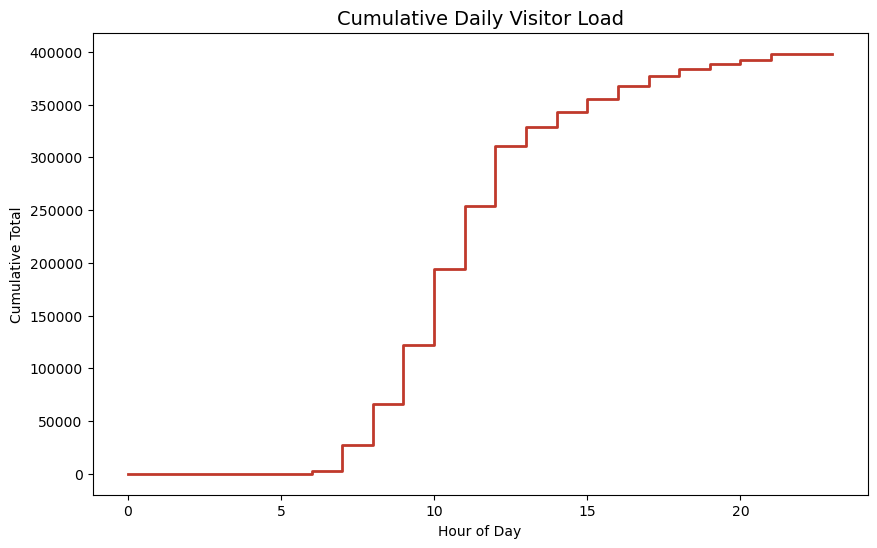

In [22]:
plt.figure(figsize=(10, 6))
cumulative_hours = master_df.groupby('START_HOUR').size().cumsum()
plt.step(cumulative_hours.index, cumulative_hours.values, where='post', color='#c0392b', linewidth=2)
plt.title('Cumulative Daily Visitor Load', fontsize=14)
plt.xlabel('Hour of Day')
plt.ylabel('Cumulative Total')

#### 2.2(f) Create a Column Chart of Average Duration per Hour

Text(0, 0.5, 'Avg Duration (Minutes)')

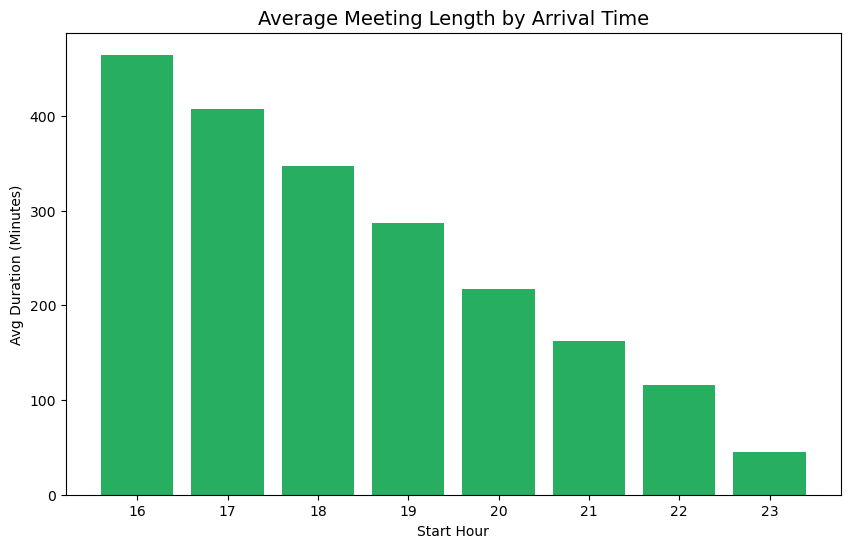

In [23]:
plt.figure(figsize=(10, 6))
# Filtering for realistic meeting durations (e.g., 0 to 480 mins) to remove outliers
mask = (master_df['DURATION_MIN'] > 0) & (master_df['DURATION_MIN'] < 480)
avg_duration = master_df[mask].groupby('START_HOUR')['DURATION_MIN'].mean()
plt.bar(avg_duration.index, avg_duration.values, color='#27ae60')
plt.title('Average Meeting Length by Arrival Time', fontsize=14)
plt.xlabel('Start Hour')
plt.ylabel('Avg Duration (Minutes)')